<a href="https://colab.research.google.com/github/milk1833/4IZ503-movielens-imdb/blob/main/%C3%BAvodn%C3%AD_zpr%C3%A1va.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from datetime import date

# ---------- NASTAVENÍ ----------
VERZE = "ml-25m"          # pro rychlý test: "ml-latest-small"
NACIST_VELKE = False      # True = přidá n_akas, n_regions, n_languages, n_principals, n_categories (pomalé, desítky minut)
# --------------------------------

# 1) Stažení dat
!wget -nc -q https://files.grouplens.org/datasets/movielens/{VERZE}.zip
!unzip -o -q {VERZE}.zip
soubory = ["basics", "ratings", "crew"] + (["akas", "principals"] if NACIST_VELKE else [])
for f in soubory:
    !wget -nc -q https://datasets.imdbws.com/title.{f}.tsv.gz
DATUM = date.today()
print("Datum stažení:", DATUM)
P = VERZE + "/"

# 2) MovieLens
movies = pd.read_csv(P + "movies.csv").rename(columns={"genres": "genres_ml", "title": "title_ml"})
links = pd.read_csv(P + "links.csv", dtype={"imdbId": str, "tmdbId": str})
links["tmdbId"] = pd.to_numeric(links["tmdbId"], errors="coerce")
links["tconst"] = "tt" + links["imdbId"].str.zfill(7)
ratings = pd.read_csv(P + "ratings.csv", usecols=["movieId", "rating"],
                      dtype={"movieId": "int32", "rating": "float32"})
tags = pd.read_csv(P + "tags.csv", usecols=["movieId"])

ml = ratings.groupby("movieId")["rating"].agg(ml_n="count", ml_mean="mean", ml_std="std").reset_index()
hi = (ratings.assign(hi=ratings.rating >= 4).groupby("movieId")["hi"].mean()
      .rename("ml_share_high").reset_index())
n_tags = tags.groupby("movieId").size().rename("n_tags").reset_index()
del ratings

# 3) IMDb
basics_all = pd.read_csv("title.basics.tsv.gz", sep="\t", na_values="\\N", low_memory=False)
adult_ids = set(basics_all.loc[basics_all.isAdult == 1, "tconst"])
basics = basics_all[basics_all.isAdult == 0].drop(columns=["isAdult", "endYear"])
basics = basics.rename(columns={"genres": "genres_imdb"})
basics["runtimeMinutes"] = pd.to_numeric(basics["runtimeMinutes"], errors="coerce")
basics["startYear"] = pd.to_numeric(basics["startYear"], errors="coerce")
imdb_r = pd.read_csv("title.ratings.tsv.gz", sep="\t", na_values="\\N")

# 4) Spojení
film = (movies.merge(links, on="movieId", how="left")
              .merge(ml, on="movieId", how="left")
              .merge(hi, on="movieId", how="left")
              .merge(n_tags, on="movieId", how="left")
              .merge(basics, on="tconst", how="left")
              .merge(imdb_r, on="tconst", how="left"))
film["n_tags"] = film["n_tags"].fillna(0)

# 5) Velké IMDb tabulky po částech (jen filmy, které máme)
keep = set(film["tconst"].dropna())

def nacti_filtr(soubor, sloupec):
    casti = []
    for ch in pd.read_csv(soubor, sep="\t", na_values="\\N", chunksize=1_000_000, low_memory=False):
        casti.append(ch[ch[sloupec].isin(keep)])
    return pd.concat(casti)

crew = nacti_filtr("title.crew.tsv.gz", "tconst")
crew["n_directors"] = crew["directors"].fillna("").apply(lambda s: len(s.split(",")) if s else 0)
crew["n_writers"] = crew["writers"].fillna("").apply(lambda s: len(s.split(",")) if s else 0)
film = film.merge(crew[["tconst", "n_directors", "n_writers"]], on="tconst", how="left")

if NACIST_VELKE:
    akas = nacti_filtr("title.akas.tsv.gz", "titleId")
    akas_a = (akas.groupby("titleId")
                  .agg(n_akas=("title", "count"), n_regions=("region", "nunique"),
                       n_languages=("language", "nunique"))
                  .reset_index().rename(columns={"titleId": "tconst"}))
    prin = nacti_filtr("title.principals.tsv.gz", "tconst")
    prin_a = (prin.groupby("tconst")
                  .agg(n_principals=("nconst", "nunique"), n_categories=("category", "nunique"))
                  .reset_index())
    film = film.merge(akas_a, on="tconst", how="left").merge(prin_a, on="tconst", how="left")

# 6) Odvozené sloupce
film["decade"] = film["startYear"] // 10 * 10
film["rating_diff"] = film["averageRating"] - film["ml_mean"] * 2   # IMDb (0-10) minus MovieLens (0.5-5) převedené na 0-10
film["n_genres"] = film["genres_ml"].str.count(r"\|") + 1
film["spolehlivy"] = ((film["ml_n"] >= 10) & (film["numVotes"] >= 100)).astype(int)
g = film["genres_ml"].str.get_dummies("|").add_prefix("g_")
film = pd.concat([film, g], axis=1)

# 7) Kontrola správnosti spojení
print("\n=== ROZMĚR ===")
print("řádků, sloupců:", film.shape)
print("\n=== KONTROLA SPOJENÍ ===")
print("filmů v MovieLens:", len(movies), "| po spojení:", len(film), "| shodné:", len(movies) == len(film))
print("movieId unikátní:", film["movieId"].is_unique, "| tconst unikátní:", film["tconst"].is_unique)
print("má tconst:", round(film["tconst"].notna().mean(), 4))
print("spárováno s IMDb basics:", round(film["primaryTitle"].notna().mean(), 4))
print("spárováno s IMDb ratings:", round(film["averageRating"].notna().mean(), 4))
nesp = film.loc[film["primaryTitle"].isna(), "tconst"]
print("nespárováno s basics:", len(nesp), "| z toho adult tituly (vyřazeny):", nesp.isin(adult_ids).sum())
print("\nRozdělení titleType:\n", film["titleType"].value_counts(dropna=False))
print("\nPodíl spolehlivých filmů:", round(film["spolehlivy"].mean(), 3), "| počet:", film["spolehlivy"].sum())

# 8) Profil proměnných (ruční rozdělení)
id_cols = ["movieId", "imdbId", "tmdbId", "tconst"]
text_cols = ["title_ml", "primaryTitle", "originalTitle", "genres_ml", "genres_imdb"]
bin_cols = [c for c in film.columns if c.startswith("g_")] + ["spolehlivy"]
kat_cols = ["titleType", "decade", "n_genres"]
spoj_cols = [c for c in film.columns if c not in id_cols + text_cols + bin_cols + kat_cols]

typy = {**{c: "identifikátor" for c in id_cols}, **{c: "textová" for c in text_cols},
        **{c: "binární" for c in bin_cols}, **{c: "kategoriální" for c in kat_cols},
        **{c: "spojitá/počet" for c in spoj_cols}}
p = pd.DataFrame({"typ": pd.Series(typy),
                  "dtype": film.dtypes.astype(str),
                  "chybi_%": (film.isna().mean() * 100).round(1),
                  "unikatni": film.nunique()}).loc[film.columns]
pd.set_option("display.max_rows", 200)
print("\n=== PROFIL PROMĚNNÝCH ===")
print(p)
print("\n=== POČET PODLE TYPU ===")
print(p["typ"].value_counts())
print("\nSouhrn spojitých:\n", film[spoj_cols].describe().T.round(2))

film.to_csv("film.csv", index=False)
p.to_csv("profil.csv")
print("\nUloženo: film.csv, profil.csv | datum stažení:", DATUM)

Datum stažení: 2026-10-17

=== ROZMĚR ===
řádků, sloupců: (62423, 45)

=== KONTROLA SPOJENÍ ===
filmů v MovieLens: 62423 | po spojení: 62423 | shodné: True
movieId unikátní: True | tconst unikátní: True
má tconst: 1.0
spárováno s IMDb basics: 0.9975
spárováno s IMDb ratings: 0.9971
nespárováno s basics: 158 | z toho adult tituly (vyřazeny): 29

Rozdělení titleType:
 titleType
movie           52817
tvMovie          3600
short            2790
video            1535
tvSpecial         527
tvMiniSeries      454
tvEpisode         368
NaN               158
tvShort            89
tvSeries           85
Name: count, dtype: int64

Podíl spolehlivých filmů: 0.388 | počet: 24231

=== PROFIL PROMĚNNÝCH ===
                                typ    dtype  chybi_%  unikatni
movieId               identifikátor    int64      0.0     62423
title_ml                    textová   object      0.0     62325
genres_ml                   textová   object      0.0      1639
imdbId                identifikátor   object

Všechny záznamy: 62423 | filmy (movie): 52817 | spolehlivé filmy: 21869

decade:
 decade
1900.0        1
1910.0      124
1920.0      454
1930.0     1808
1940.0     2081
1950.0     2743
1960.0     3341
1970.0     4431
1980.0     4456
1990.0     5400
2000.0    10277
2010.0    17678
2020.0       17
Name: count, dtype: int64

n_genres:
 n_genres
1     24935
2     16131
3      8631
4      2391
5       590
6       112
7        24
8         2
10        1
Name: count, dtype: int64

Počet žánrů: 19 
 g_Drama          23324
g_Comedy         14664
g_Thriller        7818
g_Romance         7142
g_Action          6520
g_Horror          5179
g_Crime           4915
g_Documentary     4350
g_Adventure       3605
g_Sci-Fi          2856
g_Mystery         2577
g_Fantasy         2117
g_Children        1924
g_War             1712
g_Western         1302
g_Animation       1271
g_Musical          988
g_Film-Noir        351
g_IMAX             176
dtype: int64

 cat_imdb 
 cat_imdb
nízké      1679
střední    8784

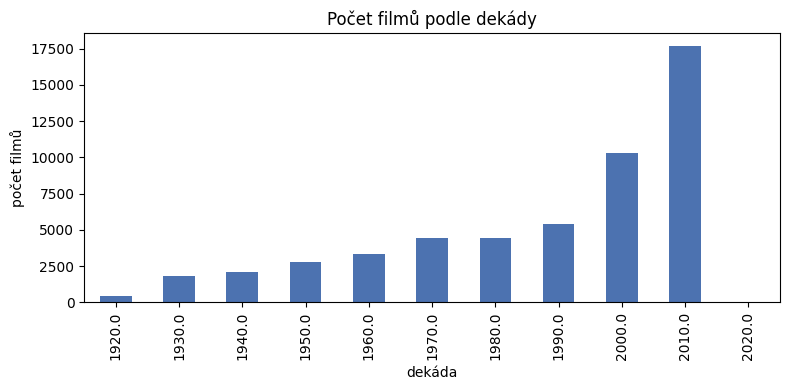

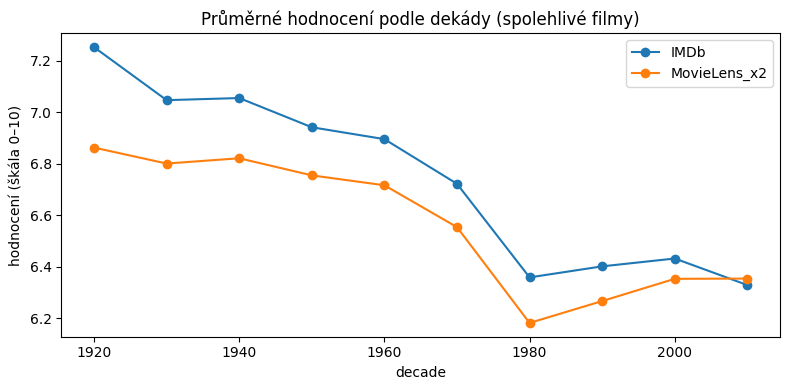

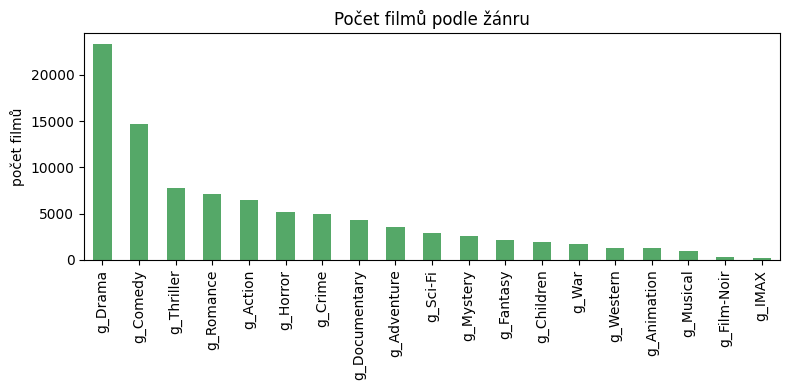

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1) Jen celovečerní filmy
fm = film[film["titleType"] == "movie"].copy()
sp = fm[fm["spolehlivy"] == 1].copy()          # alespoň 10 hodnocení v MovieLens a 100 hlasů na IMDb
print("Všechny záznamy:", len(film), "| filmy (movie):", len(fm), "| spolehlivé filmy:", len(sp))

# 2) Kategoriální proměnné: počty kategorií a četnosti
print("\ndecade:\n", fm["decade"].value_counts().sort_index())
print("\nn_genres:\n", fm["n_genres"].value_counts().sort_index())
gcols = [c for c in fm.columns if c.startswith("g_") and c != "g_(no genres listed)"]
zanry = fm[gcols].sum().sort_values(ascending=False)
print("\nPočet žánrů:", len(gcols), "\n", zanry)

# 3) Návrh kategorizace pro GUHA (na spolehlivých filmech)
sp["cat_imdb"]   = pd.cut(sp["averageRating"], [0, 5, 6.5, 7.5, 10], labels=["nízké", "střední", "vysoké", "výborné"])
sp["cat_ml"]     = pd.cut(sp["ml_mean"] * 2, [0, 5, 6.5, 7.5, 10], labels=["nízké", "střední", "vysoké", "výborné"])
sp["cat_votes"]  = pd.qcut(sp["numVotes"], 3, labels=["málo hlasů", "středně", "hodně hlasů"])
sp["cat_runtime"] = pd.cut(sp["runtimeMinutes"], [0, 80, 100, 130, 1000], labels=["krátký", "standardní", "delší", "dlouhý"])
sp["cat_diff"]   = pd.cut(sp["rating_diff"], [-10, -0.5, 0.5, 10], labels=["IMDb nižší", "podobné", "IMDb vyšší"])
for c in ["cat_imdb", "cat_ml", "cat_votes", "cat_runtime", "cat_diff"]:
    print("\n", c, "\n", sp[c].value_counts().sort_index())

# 4) Ukázky BI (obrázky pro prezentaci)
dec = fm[fm["decade"] >= 1920]
plt.figure(figsize=(8, 4))
dec.groupby("decade").size().plot(kind="bar", color="#4C72B0")
plt.title("Počet filmů podle dekády"); plt.xlabel("dekáda"); plt.ylabel("počet filmů"); plt.tight_layout()
plt.savefig("graf1_pocet_filmu_dekada.png", dpi=150); plt.show()

d2 = sp[sp["decade"] >= 1920].groupby("decade").agg(IMDb=("averageRating", "mean"), MovieLens_x2=("ml_mean", lambda s: (s * 2).mean()))
plt.figure(figsize=(8, 4))
d2.plot(marker="o", ax=plt.gca())
plt.title("Průměrné hodnocení podle dekády (spolehlivé filmy)"); plt.ylabel("hodnocení (škála 0–10)"); plt.tight_layout()
plt.savefig("graf2_hodnoceni_dekada.png", dpi=150); plt.show()

plt.figure(figsize=(8, 4))
zanry.plot(kind="bar", color="#55A868")
plt.title("Počet filmů podle žánru"); plt.ylabel("počet filmů"); plt.tight_layout()
plt.savefig("graf3_zanry.png", dpi=150); plt.show()

from google.colab import files
for f in ["graf1_pocet_filmu_dekada.png", "graf2_hodnoceni_dekada.png", "graf3_zanry.png"]:
    files.download(f)

In [ ]:
print(fm["ml_n"].median(), fm["ml_n"].isna().mean() * 100)

7.0 5.534203002821061


In [ ]:
import gzip

def radku_gz(soubor):
    with gzip.open(soubor, "rt", encoding="utf-8") as f:
        return sum(1 for _ in f) - 1          # minus řádek s hlavičkou

def radku_csv(soubor):
    with open(soubor, encoding="utf-8") as f:
        return sum(1 for _ in f) - 1

print("=== IMDb ===")
for s in ["title.basics.tsv.gz", "title.ratings.tsv.gz", "title.crew.tsv.gz"]:
    print(s, f"{radku_gz(s):,}".replace(",", " "))

print("\n=== MovieLens ===")
for s in ["movies", "ratings", "tags", "links"]:
    print(s, f"{radku_csv('ml-25m/' + s + '.csv'):,}".replace(",", " "))

=== IMDb ===
title.basics.tsv.gz 12 869 324
title.ratings.tsv.gz 1 721 745
title.crew.tsv.gz 12 870 865

=== MovieLens ===
movies 62 423
ratings 25 000 095
tags 1 093 360
links 62 423


In [ ]:
# Důkaz ke grafu 2: průměrné hodnocení podle dekády (spolehlivé filmy)
dk = (sp.groupby("decade")
        .agg(pocet_filmu=("movieId", "count"),
             imdb_prumer=("averageRating", "mean"),
             ml_prumer=("ml_mean", "mean"))
        .round(2))
dk["ml_x2"] = (dk["ml_prumer"] * 2).round(2)      # MovieLens přepočtený na stupnici 0–10
dk["rozdil_imdb_minus_ml"] = (dk["imdb_prumer"] - dk["ml_x2"]).round(2)

print("Podklad ke grafu 2 (spolehlivé filmy, ml_n>=10 a numVotes>=100)")
print("Počet filmů celkem:", dk["pocet_filmu"].sum())
display(dk)

dk.to_csv("dukaz_graf2_dekady.csv")

Podklad ke grafu 2 (spolehlivé filmy, ml_n>=10 a numVotes>=100)
Počet filmů celkem: 21869


,pocet_filmu,imdb_prumer,ml_prumer,ml_x2,rozdil_imdb_minus_ml
decade,,,,,
1910.0,23,6.86,3.22,6.44,0.42
1920.0,137,7.25,3.43,6.86,0.39
1930.0,428,7.05,3.40,6.80,0.25
1940.0,607,7.06,3.41,6.82,0.24
1950.0,804,6.94,3.38,6.76,0.18
1960.0,1136,6.90,3.36,6.72,0.18
1970.0,1354,6.72,3.28,6.56,0.16
1980.0,2118,6.36,3.09,6.18,0.18
1990.0,3282,6.40,3.13,6.26,0.14
